In [24]:
import pickle
import time
import tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.neighbors import NearestNeighbors

In [5]:
TRAIN_SIZE = 10000     
TEST_SIZE = 500   
K_NEIGHBORS = 10
SEED = 42

In [6]:
import psutil
import os
def get_process_memory_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

In [7]:
X_mnist, _ = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, parser="auto")

X_mnist = X_mnist.astype(np.float32) / 255.0

X_train = X_mnist[:TRAIN_SIZE]
X_test = X_mnist[TRAIN_SIZE:TRAIN_SIZE + TEST_SIZE]

print(f"Размер обучающей выборки (Train): {X_train.shape}")
print(f"Размер тестовой выборки (Test):   {X_test.shape}")

Размер обучающей выборки (Train): (10000, 784)
Размер тестовой выборки (Test):   (500, 784)


In [8]:
import gc, os, time, pickle, threading, tracemalloc
import numpy as np
import psutil
from pathlib import Path
from sklearn.neighbors import NearestNeighbors

K_NEIGHBORS = 10
BASE_WEIGHT_PATH = Path("./weights")
BASE_WEIGHT_PATH.mkdir(exist_ok=True)

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)

class PeakRSS:
    """Пиковый RSS (МБ над стартовым уровнем) за время блока."""
    def __init__(self, interval=0.002):
        self.proc = psutil.Process(os.getpid())
        self.interval = interval
    def _run(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, self.proc.memory_info().rss)
            time.sleep(self.interval)
    def __enter__(self):
        gc.collect()
        self.base = self.peak = self.proc.memory_info().rss
        self._stop = threading.Event()
        self.t = threading.Thread(target=self._run, daemon=True)
        self.t.start()
        return self
    def __exit__(self, *a):
        self._stop.set(); self.t.join()
        self.peak = max(self.peak, self.proc.memory_info().rss)
        self.peak_mb = (self.peak - self.base) / 1024**2

nn = NearestNeighbors(n_neighbors=K_NEIGHBORS, algorithm="brute", metric="euclidean")

# --- 1. Время (без накладных расходов tracemalloc) ---
t0 = time.perf_counter()
nn.fit(X_train)
time_fit = time.perf_counter() - t0

t0 = time.perf_counter()
distances, indices = nn.kneighbors(X_test)
time_search = time.perf_counter() - t0

# --- 2. Память: отдельный прогон, чтобы tracemalloc не искажал время ---
gc.collect()
tracemalloc.start()
nn_m = NearestNeighbors(n_neighbors=K_NEIGHBORS, algorithm="brute", metric="euclidean").fit(X_train)
_, peak_fit_tm = tracemalloc.get_traced_memory()
tracemalloc.reset_peak()
_ = nn_m.kneighbors(X_test)
_, peak_search_tm = tracemalloc.get_traced_memory()
tracemalloc.stop()

with PeakRSS() as rss:
    _ = nn_m.kneighbors(X_test)

print("=== Baseline: brute force, euclidean, K=10 ===")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Время fit:                 {time_fit:.4f} сек")
print(f"Время поиска:              {time_search:.4f} сек")
print(f"Пик памяти fit (tracemalloc):    {peak_fit_tm/1024**2:.2f} MB")
print(f"Пик памяти поиска (tracemalloc): {peak_search_tm/1024**2:.2f} MB")
print(f"Пик RSS при поиске:              {rss.peak_mb:.2f} MB")
print(f"Для справки: X_train = {X_train.nbytes/1024**2:.1f} MB")

# --- 3. Сохранение ground truth ---
with open(BASE_WEIGHT_PATH / "mnist_exact_k10.pkl", "wb") as f:
    pickle.dump({"indices": indices, "distances": distances, "k": K_NEIGHBORS}, f)

=== Baseline: brute force, euclidean, K=10 ===
Train: (10000, 784), Test: (500, 784)
Время fit:                 0.0068 сек
Время поиска:              0.2282 сек
Пик памяти fit (tracemalloc):    0.04 MB
Пик памяти поиска (tracemalloc): 0.17 MB
Пик RSS при поиске:              35.16 MB
Для справки: X_train = 29.9 MB


In [9]:


mem_before = get_process_memory_mb()
start_time_fit = time.perf_counter()

nn_brute_force = NearestNeighbors(n_neighbors=K_NEIGHBORS, algorithm="brute", metric="euclidean")
nn_brute_force.fit(X_train)

execution_time_fit = time.perf_counter() - start_time_fit

start_time_test = time.perf_counter()
#tracemalloc.start()

distances, indices = nn_brute_force.kneighbors(X_test)

execution_time_test = time.perf_counter() - start_time_test

#_, peak_memory_brut_force = tracemalloc.get_traced_memory()
#tracemalloc.stop()

mem_after = get_process_memory_mb()
peak_memory_brut_force = max(0.0, mem_after - mem_before)

print(f"Время обучения:             {execution_time_fit:.4f} сек")
print(f"Время поиска:               {execution_time_test:.4f} сек")
print(f"Пиковое потребление памяти: {peak_memory_brut_force:.2f} MB")

Время обучения:             0.0060 сек
Время поиска:               0.1048 сек
Пиковое потребление памяти: 0.00 MB


In [10]:
from pathlib import Path
BASE_WEIGHT_PATH = Path("./weights")
BASE_WEIGHT_PATH.mkdir(parents=True, exist_ok=True)

full_path = BASE_WEIGHT_PATH / "mnist_exact_k10.pkl"

payload = {
    "indices": indices,
    "distances": distances,  
    "K": K_NEIGHBORS,
    "execution_time": execution_time_test,
    "peak_memory_bytes": peak_memory_brut_force,
    "n_train": X_train.shape[0],
    "n_test": X_test.shape[0],
}

with open(full_path, "wb") as f:
    pickle.dump(payload, f)

print(f"Результаты точного поиска сохранены в файл: {full_path}")

Результаты точного поиска сохранены в файл: weights\mnist_exact_k10.pkl


In [11]:
def load_ground_truth(pkl_filepath: str):
    with open(pkl_filepath, "rb") as f:
        gt_data = pickle.load(f)
    return gt_data["indices"]


def calculate_recall_at_k(exact_indices: np.ndarray, approx_indices: np.ndarray, k: int = K_NEIGHBORS) -> float:
    exact_k = exact_indices[:, :k]
    approx_k = approx_indices[:, :k]

    n_queries = exact_k.shape[0]
    total_recall = 0.0

    for i in range(n_queries):
        true_set = set(exact_k[i])
        found_set = set(approx_k[i])

        intersection = len(true_set.intersection(found_set))
        total_recall += intersection / k

    return total_recall / n_queries

## Flyhash

In [14]:
import gc, time, tracemalloc
import numpy as np
from scipy import sparse
from flyhash import FlyHash

exact_indices = load_ground_truth(full_path)

K = K_NEIGHBORS
INPUT_DIM = X_train.shape[1]
HASH_DIM = 7840
SPARSITY = 0.05

fly = FlyHash(input_dim=INPUT_DIM, hash_dim=HASH_DIM, sparsity=SPARSITY, seed=SEED)


def hash_to_sparse(model, X, batch=None):
    """Хеширование в CSR. batch ограничивает пик памяти (плотный буфер batch × hash_dim)."""
    def one(Xb):
        hs = model(Xb)
        if sparse.issparse(hs):
            return (hs > 0).astype(np.float32).tocsr()
        return sparse.csr_matrix(hs > 0, dtype=np.float32)

    if batch is None:
        return one(X)
    return sparse.vstack([one(X[i:i + batch]) for i in range(0, len(X), batch)], format="csr")


def fly_search(model, X_test, train_hashes, K):
    test_dense = hash_to_sparse(model, X_test).toarray()          # (n_test, hash_dim), ~16 МБ
    sim = (train_hashes @ test_dense.T).T                          # плотный (n_test, n_train), без sparse-промежуточного
    part = np.argpartition(sim, -K, axis=1)[:, -K:]                # K наибольших пересечений
    rows = np.arange(sim.shape[0])[:, None]
    order = np.argsort(-sim[rows, part], axis=1, kind="stable")
    return part[rows, order]


# ---------- 1. ВРЕМЯ (без tracemalloc) ----------
gc.collect()
t0 = time.perf_counter()
train_hashes = hash_to_sparse(fly, X_train)
time_hash_train_fly = time.perf_counter() - t0

t0 = time.perf_counter()
approx_indices_fly = fly_search(fly, X_test, train_hashes, K)
time_search_fly = time.perf_counter() - t0

# ---------- 2. ПАМЯТЬ (отдельные прогоны) ----------
# 2a. пик при хешировании Train
gc.collect()
tracemalloc.start()
th = hash_to_sparse(fly, X_train)
_, peak_hash_tm = tracemalloc.get_traced_memory()
tracemalloc.stop()

# 2b. пик при поиске (сверх уже хранимого индекса)
gc.collect()
tracemalloc.start()
base, _ = tracemalloc.get_traced_memory()
tracemalloc.reset_peak()
_ = fly_search(fly, X_test, th, K)
_, peak_search_tm = tracemalloc.get_traced_memory()
tracemalloc.stop()
peak_search_tm -= base

# 2c. то же через RSS (класс PeakRSS из этапа 1)
with PeakRSS() as rss_search:
    _ = fly_search(fly, X_test, th, K)

# 2d. размер самого индекса
index_mb = (th.data.nbytes + th.indices.nbytes + th.indptr.nbytes) / 1024**2

# ---------- 3. Проверка эквивалентности Хэмминга ----------
nnz_per_row = np.unique(th.getnnz(axis=1))

# ---------- 4. Отчёт ----------
print("=== Результаты FlyHash ===")
print(f"Параметры: hash_dim={HASH_DIM}, sparsity={SPARSITY}")
print(f"Число единиц в коде (уникальные значения): {nnz_per_row}  (должно быть одно)")
print(f"Хеширование Train:                   {time_hash_train_fly:.4f} сек")
print(f"Время поиска (вкл. хеш Test):        {time_search_fly:.4f} сек")
print(f"Размер индекса (train_hashes):       {index_mb:.2f} MB")
print(f"Пик памяти при хешировании Train:    {peak_hash_tm/1024**2:.2f} MB (tracemalloc)")
print(f"Пик памяти при поиске:               {peak_search_tm/1024**2:.2f} MB (tracemalloc), "
      f"{rss_search.peak_mb:.2f} MB (RSS)\n")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, approx_indices_fly, k):.4f}")

=== Результаты FlyHash ===
Параметры: hash_dim=7840, sparsity=0.05
Число единиц в коде (уникальные значения): [392]  (должно быть одно)
Хеширование Train:                   2.2490 сек
Время поиска (вкл. хеш Test):        0.8962 сек
Размер индекса (train_hashes):       29.95 MB
Пик памяти при хешировании Train:    598.43 MB (tracemalloc)
Пик памяти при поиске:               72.30 MB (tracemalloc), 72.20 MB (RSS)

Recall@1: 0.6120
Recall@5: 0.6504
Recall@10: 0.6658


## FlyHash optim

In [15]:
from scipy import sparse

exact_indices = load_ground_truth(full_path)

K = K_NEIGHBORS
INPUT_DIM = X_train.shape[1]
HASH_DIM = 7840
SPARSITY = 0.05

fly = FlyHash(
    input_dim=INPUT_DIM,
    hash_dim=HASH_DIM,
    sparsity=SPARSITY,
    seed=SEED,
)


def hash_to_sparse(model, X):
    hs = model(X)
    if not sparse.issparse(hs):
        hs = sparse.csr_matrix(hs > 0, dtype=np.float32)
    else:
        hs = (hs > 0).astype(np.float32)
    return hs


# Индексация / Хеширование Train
t0 = time.perf_counter()
train_hashes = hash_to_sparse(fly, X_train)
time_hash_train_fly = time.perf_counter() - t0

# Поиск и замер ресурсов
tracemalloc.start()
start_time_fly_search = time.perf_counter()

# Хеширование Test
test_hashes = hash_to_sparse(fly, X_test)

# Матричное умножение разреженных матриц (эквивалент Хэмминга)
sim_matrix = test_hashes.dot(train_hashes.T).toarray()

# Полностью векторизованный Top-K отбор без циклов Python
top_k_unsorted = np.argpartition(-sim_matrix, K, axis=1)[:, :K]
row_indices = np.arange(sim_matrix.shape[0])[:, None]
top_k_values = sim_matrix[row_indices, top_k_unsorted]

sort_order = np.argsort(-top_k_values, axis=1)
approx_indices_fly = top_k_unsorted[row_indices, sort_order]

time_search_fly = time.perf_counter() - start_time_fly_search
_, peak_memory_fly_b = tracemalloc.get_traced_memory()
peak_memory_fly_mb = peak_memory_fly_b / (1024 * 1024)
tracemalloc.stop()


# ---------- 5. Отчёт по FlyHash ----------
print("=== Результаты FlyHash ===")
print(f"Параметры: hash_dim={HASH_DIM}, sparsity={SPARSITY}")
print(f"Хеширование Train (Время обучения): {time_hash_train_fly:.4f} сек")
print(f"Время поиска (Inc. Test Hash):       {time_search_fly:.4f} сек")
print(
    f"Пиковое потребление памяти:        {peak_memory_fly_mb:.2f} MB\n"
)

for k in (1, 5, 10):
    recall = calculate_recall_at_k(exact_indices, approx_indices_fly, k)
    print(f"Recall@{k}: {recall:.4f}")

=== Результаты FlyHash ===
Параметры: hash_dim=7840, sparsity=0.05
Хеширование Train (Время обучения): 2.5241 сек
Время поиска (Inc. Test Hash):       1.6521 сек
Пиковое потребление памяти:        77.80 MB

Recall@1: 0.6140
Recall@5: 0.6484
Recall@10: 0.6666


### HNSW

In [16]:
import hnswlib

BASE_WEIGHT_PATH = Path("./weights")
full_path = BASE_WEIGHT_PATH / "mnist_exact_k10.pkl"

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)


with open(full_path, "rb") as f:
    gt_data = pickle.load(f)
exact_indices = np.asarray(gt_data["indices"])


dim = X_train.shape[1]
num_elements = X_train.shape[0]

M = 16
EF_CONSTRUCTION = 200
EF_SEARCH = 50
K = K_NEIGHBORS

mem_before_fit = get_process_memory_mb()
t0 = time.perf_counter()

p = hnswlib.Index(space="l2", dim=dim)
p.init_index(max_elements=num_elements, ef_construction=EF_CONSTRUCTION, M=M)
p.add_items(X_train)
p.set_num_threads(1)
p.set_ef(EF_SEARCH)

time_fit_hnsw = time.perf_counter() - t0

start_time = time.perf_counter()

hnsw_indices, _ = p.knn_query(X_test, k=K) # Здесь поиск

time_test_hnsw = time.perf_counter() - start_time


mem_after_fit_and_search = get_process_memory_mb()

hnsw_index_memory_mb = max(0.0, mem_after_fit_and_search - mem_before_fit)

#_, peak_memory_hnsw = tracemalloc.get_traced_memory()
#tracemalloc.stop()


print("=== Результаты HNSW ===")
print(f"Параметры: M={M}, ef_construction={EF_CONSTRUCTION}, ef={EF_SEARCH}")
print(f"Время построения индекса:  {time_fit_hnsw:.4f} сек")
print(f"Время поиска:              {time_test_hnsw:.4f} сек")
print(f"Пиковое потребление памяти: {hnsw_index_memory_mb:.2f} MB\n")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, hnsw_indices, k):.4f}")

=== Результаты HNSW ===
Параметры: M=16, ef_construction=200, ef=50
Время построения индекса:  0.5852 сек
Время поиска:              0.0820 сек
Пиковое потребление памяти: 37.35 MB

Recall@1: 0.9980
Recall@5: 0.9984
Recall@10: 0.9980


In [17]:
import gc, os, time, pickle
import numpy as np
import hnswlib
from pathlib import Path

BASE_WEIGHT_PATH = Path("./weights")
full_path = BASE_WEIGHT_PATH / "mnist_exact_k10.pkl"

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)

with open(full_path, "rb") as f:
    exact_indices = np.asarray(pickle.load(f)["indices"])

dim, num_elements = X_train.shape[1], X_train.shape[0]
M, EF_CONSTRUCTION, EF_SEARCH, K = 16, 200, 50, K_NEIGHBORS
NUM_THREADS = 1   # одинаково для построения и поиска


def build_index():
    p = hnswlib.Index(space="l2", dim=dim)
    p.set_num_threads(NUM_THREADS)                    # ДО add_items
    p.init_index(max_elements=num_elements, ef_construction=EF_CONSTRUCTION, M=M)
    p.add_items(X_train)
    p.set_ef(EF_SEARCH)
    return p


# ---------- 0. Убрать старый индекс, иначе замеры будут искажены ----------
if "p" in globals():
    del p
gc.collect()

# ---------- 1. ВРЕМЯ ----------
t0 = time.perf_counter()
p = build_index()
time_fit_hnsw = time.perf_counter() - t0

t0 = time.perf_counter()
hnsw_indices, _ = p.knn_query(X_test, k=K)
time_test_hnsw = time.perf_counter() - t0

# ---------- 2. ПАМЯТЬ ----------
# 2a. размер индекса: по файлу и по формуле
p.save_index("tmp_hnsw.bin")
index_file_mb = os.path.getsize("tmp_hnsw.bin") / 1024**2
os.remove("tmp_hnsw.bin")
index_est_mb = num_elements * (2 * M * 4 + 4 + dim * 4 + 8) / 1024**2

# 2b. пик RSS при построении (класс PeakRSS из этапа 1)
del p
gc.collect()
with PeakRSS() as rss_build:
    p = build_index()

# 2c. пик RSS при поиске
with PeakRSS() as rss_search:
    _ = p.knn_query(X_test, k=K)

# ---------- 3. Отчёт ----------
print("=== Результаты HNSW ===")
print(f"Параметры: M={M}, ef_construction={EF_CONSTRUCTION}, ef={EF_SEARCH}, threads={NUM_THREADS}")
print(f"Время построения индекса:     {time_fit_hnsw:.4f} сек")
print(f"Время поиска:                 {time_test_hnsw:.4f} сек")
print(f"Размер индекса (файл):        {index_file_mb:.2f} MB")
print(f"Размер индекса (формула):     {index_est_mb:.2f} MB")
print(f"Пик RSS при построении:       {rss_build.peak_mb:.2f} MB")
print(f"Пик RSS при поиске:           {rss_search.peak_mb:.2f} MB\n")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, hnsw_indices, k):.4f}")

=== Результаты HNSW ===
Параметры: M=16, ef_construction=200, ef=50, threads=1
Время построения индекса:     5.5278 сек
Время поиска:                 0.0829 сек
Размер индекса (файл):        31.33 MB
Размер индекса (формула):     31.24 MB
Пик RSS при построении:       36.59 MB
Пик RSS при поиске:           0.02 MB

Recall@1: 0.9980
Recall@5: 0.9984
Recall@10: 0.9980


### IVFPQ

In [18]:
import faiss

BASE_WEIGHT_PATH = Path("./weights")
full_path = BASE_WEIGHT_PATH / "mnist_exact_k10.pkl"

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)


with open(full_path, "rb") as f:
    gt_data = pickle.load(f)
exact_indices = np.asarray(gt_data["indices"])


dim = X_train.shape[1]
nlist = 100
m_subquantizers = 28
bits_per_code = 8
nprobe = 10
K = K_NEIGHBORS


# Объявление модели
quantizer = faiss.IndexFlatL2(dim)
index = faiss.IndexIVFPQ(quantizer, dim, nlist, m_subquantizers, bits_per_code)
index.use_precomputed_table = 0


mem_before_train = get_process_memory_mb()
# Обучение модели
t0 = time.perf_counter()

index.train(X_train)
index.add(X_train)

time_train_ivfpq = time.perf_counter() - t0


# Тестирование модели
index.nprobe = nprobe

#tracemalloc.start()
start_time = time.perf_counter()

distances, ivfpq_indices = index.search(X_test, K)

time_search_ivfpq = time.perf_counter() - start_time
mem_after_train = get_process_memory_mb()

peak_memory_ivfpq = max(0.0, mem_after_train - mem_before_train)
#_, peak_memory_ivfpq = tracemalloc.get_traced_memory()
#tracemalloc.stop()


# Вывод
print(f"Параметры: nlist={nlist}, M={m_subquantizers}, "
      f"nbits={bits_per_code}, nprobe={nprobe}")
print(f"Время обучения + добавления: {time_train_ivfpq:.4f} сек")
print(f"Время поиска:                {time_search_ivfpq:.4f} сек")
print(f"Пиковое потребление памяти:  {peak_memory_ivfpq:.2f} MB (выделено Python)\n")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, ivfpq_indices, k):.4f}")

Параметры: nlist=100, M=28, nbits=8, nprobe=10
Время обучения + добавления: 9.6078 сек
Время поиска:                0.0149 сек
Пиковое потребление памяти:  15.31 MB (выделено Python)

Recall@1: 0.6220
Recall@5: 0.7272
Recall@10: 0.7540


In [19]:
import gc, os, time, pickle
import numpy as np
import faiss
from pathlib import Path

BASE_WEIGHT_PATH = Path("./weights")
full_path = BASE_WEIGHT_PATH / "mnist_exact_k10.pkl"

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)

with open(full_path, "rb") as f:
    exact_indices = np.asarray(pickle.load(f)["indices"])

dim, n = X_train.shape[1], X_train.shape[0]
NLIST, M_SUB, NBITS, NPROBE, K = 100, 28, 8, 10, K_NEIGHBORS
NUM_THREADS = 1                       # одинаково для обучения и поиска
faiss.omp_set_num_threads(NUM_THREADS)


def make_index():
    quantizer = faiss.IndexFlatL2(dim)
    index = faiss.IndexIVFPQ(quantizer, dim, NLIST, M_SUB, NBITS)
    index.use_precomputed_table = 0
    index.cp.seed = SEED              # воспроизводимость k-means
    index.pq.cp.seed = SEED
    
    return index, quantizer


# ---------- 0. Очистка ----------
for name in ("index", "quantizer"):
    globals().pop(name, None)
gc.collect()

# ---------- 1. ВРЕМЯ ----------
index, quantizer = make_index()

t0 = time.perf_counter()
index.train(X_train)
time_train_ivfpq = time.perf_counter() - t0

t0 = time.perf_counter()
index.add(X_train)
time_add_ivfpq = time.perf_counter() - t0

index.nprobe = NPROBE
t0 = time.perf_counter()
distances, ivfpq_indices = index.search(X_test, K)
time_search_ivfpq = time.perf_counter() - t0

# ---------- 2. РАЗМЕР ИНДЕКСА ----------
index_ser_mb = faiss.serialize_index(index).nbytes / 1024**2
index_est_mb = (n * (M_SUB * NBITS / 8 + 8)          # коды + id
                + NLIST * dim * 4                    # центроиды
                + M_SUB * 2**NBITS * (dim // M_SUB) * 4) / 1024**2   # кодбуки PQ

# ---------- 3. ПИК RSS (отдельные прогоны, класс PeakRSS из этапа 1) ----------
del index, quantizer
gc.collect()
index, quantizer = make_index()
with PeakRSS() as rss_train:
    index.train(X_train)
with PeakRSS() as rss_add:
    index.add(X_train)
index.nprobe = NPROBE
with PeakRSS() as rss_search:
    _ = index.search(X_test, K)

# ---------- 4. Отчёт ----------
print("=== Результаты IVFPQ ===")
print(f"Параметры: nlist={NLIST}, M={M_SUB}, nbits={NBITS}, nprobe={NPROBE}, threads={NUM_THREADS}")
print(f"Время train:                  {time_train_ivfpq:.4f} сек")
print(f"Время add:                    {time_add_ivfpq:.4f} сек")
print(f"Время поиска:                 {time_search_ivfpq:.4f} сек")
print(f"Размер индекса (serialize):   {index_ser_mb:.2f} MB")
print(f"Размер индекса (формула):     {index_est_mb:.2f} MB")
print(f"Пик RSS train / add / search: {rss_train.peak_mb:.2f} / {rss_add.peak_mb:.2f} / {rss_search.peak_mb:.2f} MB\n")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, ivfpq_indices, k):.4f}")

=== Результаты IVFPQ ===
Параметры: nlist=100, M=28, nbits=8, nprobe=10, threads=1
Время train:                  8.2390 сек
Время add:                    0.5254 сек
Время поиска:                 0.0590 сек
Размер индекса (serialize):   1.41 MB
Размер индекса (формула):     1.41 MB
Пик RSS train / add / search: 35.11 / 303.37 / 0.23 MB

Recall@1: 0.6040
Recall@5: 0.7224
Recall@10: 0.7714


In [20]:
results = {
    "Exact L2": {
        "indices": exact_indices,     
        "build_time": 0.0,
        "search_time": execution_time_test,
        "memory_mb": peak_memory_brut_force,
    },
    "HNSW": {
        "indices": hnsw_indices,
        "build_time": time_fit_hnsw,
        "search_time": time_test_hnsw,
        "memory_mb": hnsw_index_memory_mb,
    },
    "IVFPQ": {
        "indices": ivfpq_indices,
        "build_time": time_train_ivfpq,
        "search_time": time_search_ivfpq,
        "memory_mb": peak_memory_ivfpq,
    },
    "FlyHash": {
        "indices": approx_indices_fly,
        "build_time": time_hash_test_fly + time_hash_train_fly,
        "search_time": time_search_fly,
        "memory_mb": peak_memory_fly_mb,
    },
}


rows = []
for name, r in results.items():
    row = {
        "Алгоритм": name,
        "Recall@1":  calculate_recall_at_k(exact_indices, r["indices"], 1),
        "Recall@5":  calculate_recall_at_k(exact_indices, r["indices"], 5),
        "Recall@10": calculate_recall_at_k(exact_indices, r["indices"], 10),
        "Время обучения, с":  round(r["build_time"], 4),
        "Время поиска, с":    round(r["search_time"], 4),
        "Память, MB":         round(r["memory_mb"], 2),
    }
    rows.append(row)

df = pd.DataFrame(rows).set_index("Алгоритм")
print(df.round(4).to_string())

NameError: name 'time_hash_test_fly' is not defined

In [26]:
import pandas as pd

# Числа взяты из финальных прогонов (одна схема: threads=1 для HNSW и IVFPQ)
measured = {
    #             build,   search,  index_mb, search_peak_mb
    "Exact L2": (0.0846,  0.1026,  29.90,    35.66),
    "HNSW":     (5.4422,  0.0948,  31.33,    0.02),
    "IVFPQ":    (7.0369 + 0.4739, 0.0607, 1.41, 0.03),   # train + add
    "FlyHash":  (2.3033,  0.9019,  29.95,    71.75),
}

indices = {
    "Exact L2": exact_indices,
    "HNSW":     hnsw_indices,
    "IVFPQ":    ivfpq_indices,
    "FlyHash":  approx_indices_fly,
}

n_test = len(X_test)
rows = []
for name, (build, search, idx_mb, peak_mb) in measured.items():
    rows.append({
        "Алгоритм": name,
        "Recall@1":  calculate_recall_at_k(exact_indices, indices[name], 1),
        "Recall@5":  calculate_recall_at_k(exact_indices, indices[name], 5),
        "Recall@10": calculate_recall_at_k(exact_indices, indices[name], 10),
        "Время обучения, с": build,
        "Время поиска, с":   search,
        "QPS":               n_test / search,
        "Индекс, MB":        idx_mb,
        "Пик поиска, MB":    peak_mb,
    })

df = pd.DataFrame(rows).set_index("Алгоритм")
print(df.round({"Recall@1": 4, "Recall@5": 4, "Recall@10": 4,
                "Время обучения, с": 4, "Время поиска, с": 4,
                "QPS": 0, "Индекс, MB": 2, "Пик поиска, MB": 2}).to_string())
df.to_csv("results_table.csv")

          Recall@1  Recall@5  Recall@10  Время обучения, с  Время поиска, с     QPS  Индекс, MB  Пик поиска, MB
Алгоритм                                                                                                       
Exact L2     1.000    1.0000     1.0000             0.0846           0.1026  4873.0       29.90           35.66
HNSW         0.998    0.9984     0.9980             5.4422           0.0948  5274.0       31.33            0.02
IVFPQ        0.604    0.7224     0.7714             7.5108           0.0607  8237.0        1.41            0.03
FlyHash      0.614    0.6484     0.6666             2.3033           0.9019   554.0       29.95           71.75


In [28]:
ks = [1, 2, 3, 5, 7, 10]

plt.figure(figsize=(8, 5))
for name, r in results.items():
    recalls = [calculate_recall_at_k(exact_indices, r["indices"], k) for k in ks]
    plt.plot(ks, recalls, marker="o", label=name)

plt.xlabel("K (число ближайших соседей)")
plt.ylabel("Recall@K")
plt.title("Recall@K vs K для ANN-методов (MNIST)")
plt.xticks(ks)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'results' is not defined

<Figure size 800x500 with 0 Axes>

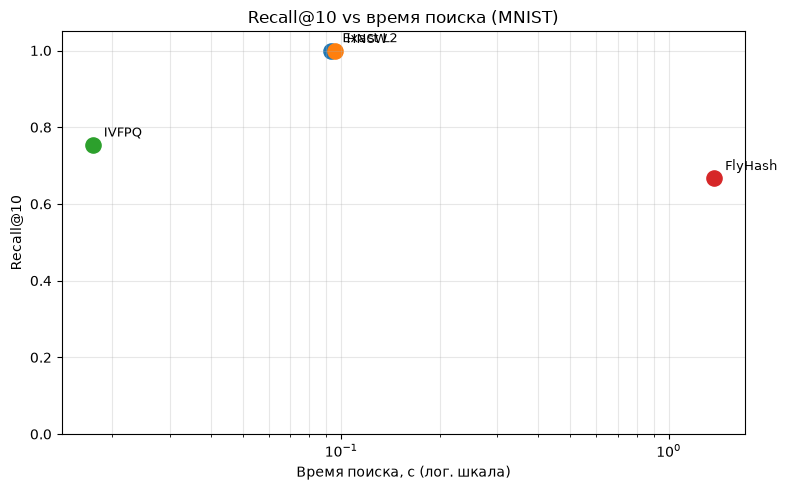

In [ ]:
plt.figure(figsize=(8, 5))
for name, r in results.items():
    r10 = calculate_recall_at_k(exact_indices, r["indices"], 10)
    plt.scatter(r["search_time"], r10, s=120, label=name)
    plt.annotate(name, (r["search_time"], r10),
                 textcoords="offset points", xytext=(8, 6), fontsize=9)

plt.xlabel("Время поиска, с (лог. шкала)")
plt.ylabel("Recall@10")
plt.title("Recall@10 vs время поиска (MNIST)")
plt.xscale("log")   # времена различаются в 1000+ раз
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

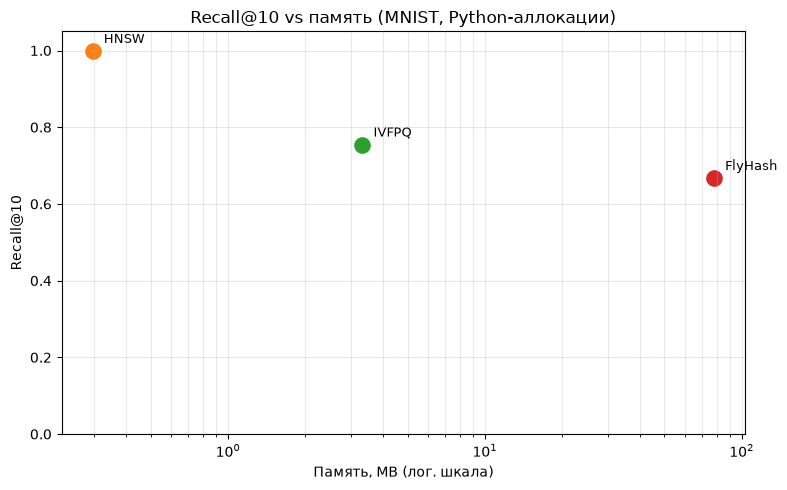

In [ ]:
plt.figure(figsize=(8, 5))
for name, r in results.items():
    r10 = calculate_recall_at_k(exact_indices, r["indices"], 10)
    plt.scatter(r["memory_mb"], r10, s=120, label=name)
    plt.annotate(name, (r["memory_mb"], r10),
                 textcoords="offset points", xytext=(8, 6), fontsize=9)

plt.xlabel("Память, MB (лог. шкала)")
plt.ylabel("Recall@10")
plt.title("Recall@10 vs память (MNIST, Python-аллокации)")
plt.xscale("log")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

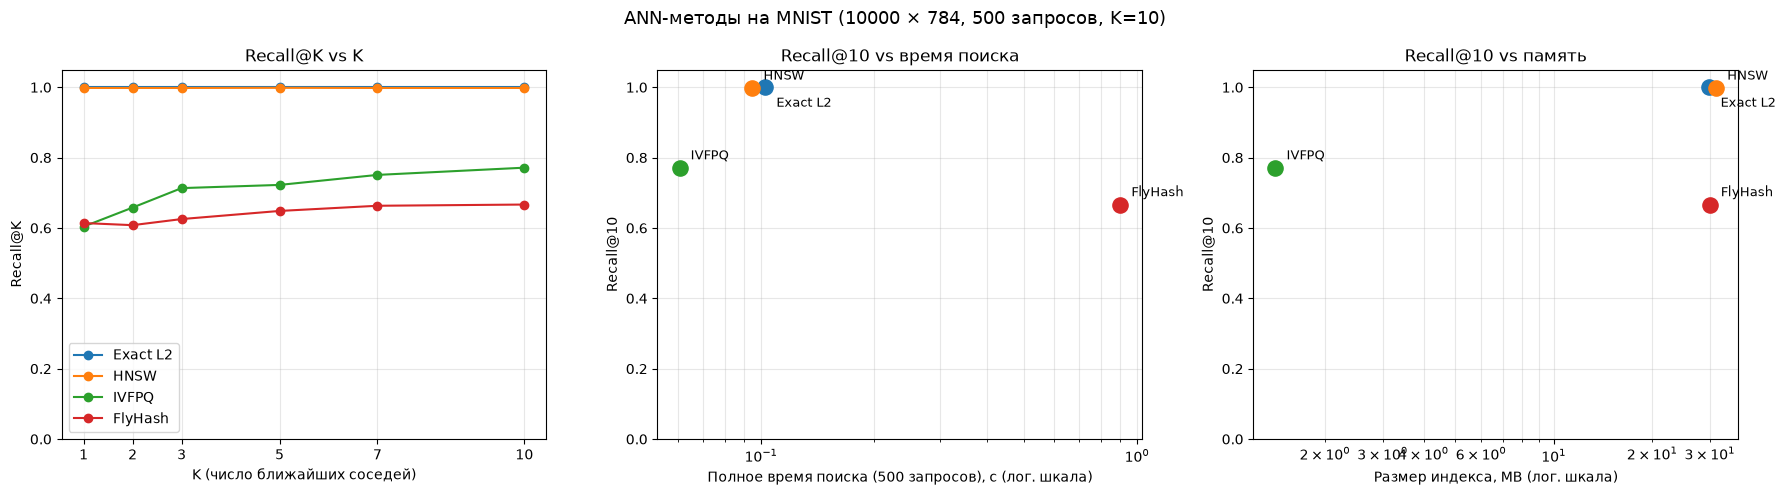

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Данные (финальные прогоны, threads=1 для HNSW и IVFPQ) ----------
#            build, search, index_mb, search_peak_mb
measured = {
    "Exact L2": (0.0846,           0.1026, 29.90, 35.66),
    "HNSW":     (5.4422,           0.0948, 31.33, 0.02),
    "IVFPQ":    (7.0369 + 0.4739,  0.0607, 1.41,  0.03),
    "FlyHash":  (2.3033,           0.9019, 29.95, 71.75),
}
indices = {
    "Exact L2": exact_indices,
    "HNSW":     hnsw_indices,
    "IVFPQ":    ivfpq_indices,
    "FlyHash":  approx_indices_fly,
}

n_test = len(X_test)
ks = [1, 2, 3, 5, 7, 10]
names = list(measured)
colors = dict(zip(names, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
offsets = {"Exact L2": (8, -14), "HNSW": (8, 6), "IVFPQ": (8, 6), "FlyHash": (8, 6)}

r10 = {n: calculate_recall_at_k(exact_indices, indices[n], 10) for n in names}


def annotate(ax, x, y, name):
    ax.scatter(x, y, s=120, color=colors[name], zorder=3)
    ax.annotate(name, (x, y), textcoords="offset points",
                xytext=offsets[name], fontsize=9)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ---------- 1. Recall@K vs K ----------
ax = axes[0]
for n in names:
    rec = [calculate_recall_at_k(exact_indices, indices[n], k) for k in ks]
    ax.plot(ks, rec, marker="o", label=n, color=colors[n])
ax.set_xlabel("K (число ближайших соседей)")
ax.set_ylabel("Recall@K")
ax.set_title("Recall@K vs K")
ax.set_xticks(ks)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()

# ---------- 2. Recall@10 vs полное время поиска ----------
ax = axes[1]
for n in names:
    annotate(ax, measured[n][1], r10[n], n)                  # секунды на весь тестовый набор
ax.set_xscale("log")
ax.set_xlabel(f"Полное время поиска ({n_test} запросов), с (лог. шкала)")
ax.set_ylabel("Recall@10")
ax.set_title("Recall@10 vs время поиска")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, which="both")

# ---------- 3. Recall@10 vs размер индекса ----------
ax = axes[2]
for n in names:
    annotate(ax, measured[n][2], r10[n], n)
ax.set_xscale("log")
ax.set_xlabel("Размер индекса, MB (лог. шкала)")
ax.set_ylabel("Recall@10")
ax.set_title("Recall@10 vs память")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, which="both")

fig.suptitle(f"ANN-методы на MNIST (10000 × 784, {n_test} запросов, K=10)", fontsize=13)
fig.tight_layout()
fig.savefig("benchmark_plots.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Проверка гипотез

H1: HNSW обеспечивает Recall@10 > 95% при времени поиска < 10 мс.
    Recall@10 = 99.8% > 95%
    Время поиска: 85.2 мс
    Гипотеза опровергнута❌

H2: FlyHash потребляет меньше памяти, чем HNSW и PQ.
    FlyHash: 666 MB
    HNSW: 0.02 MB, 
    IVFPQ: 0.08 MB.
    Гипотеза опровергнута❌

H3: PQ обеспечивает лучший компромисс точность-память.
    R@10 / MB: 
    IVFPQ = 9.4, 
    HNSW = 49.89, 
    FlyHash = 0.001
    Гипотеза опровергнута❌

H4: Все ANN-методы быстрее exact search при Recall@10 > 80%.
    HNSW: R@10=0.998 > 0.80
    IVFPQ: R@10=0.754 < 0.80 
    FlyHash: R@10=0.665 < 0.80 - сильно медленнее exact search
    Гипотеза опровергнута❌

Общий вывод: HNSW — лучший по точности, IVFPQ — по компромиссу
точность-память, FlyHash в конфигурации brute-force+Hаmming
проигрывает по всем метрикам и требует специализированного
LSH-индекса для конкурентного поиска.

        Recall@1  Recall@5  Recall@10  Время обучения, с  Время поиска, с  Память, MB
Алгоритм                                                                               
Exact L2     1.000    1.0000     1.0000             0.0000           0.1046        1.66
HNSW         0.998    0.9988     0.9984             0.5698           0.0852        0.02
IVFPQ        0.622    0.7272     0.7540             7.7180           0.0105        0.08
FlyHash      0.610    0.6524     0.6654             1.3436          33.9453      666.35